In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('student-por.csv', sep=';')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


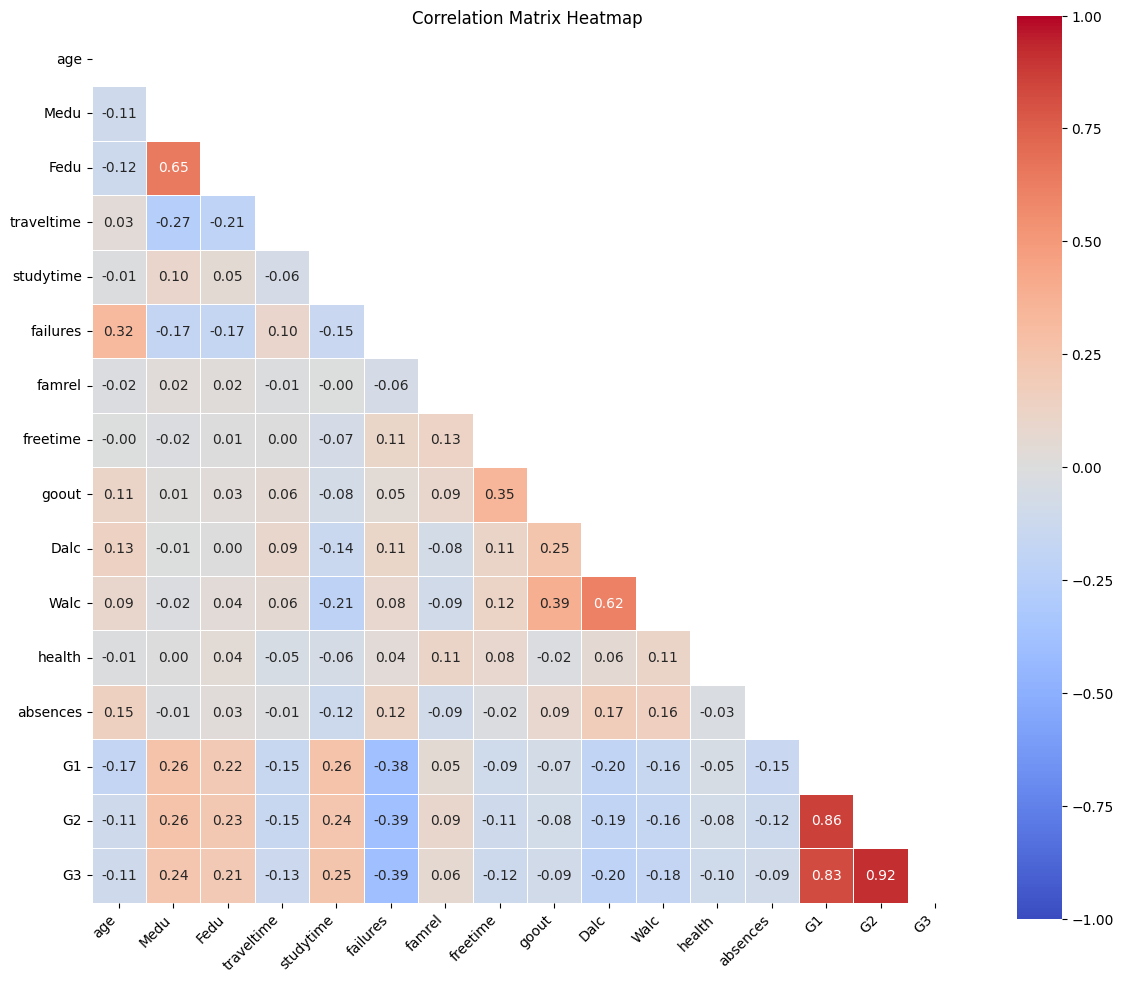

In [3]:
plt.figure(figsize=(12, 10))

corr_matrix = df.corr(numeric_only=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
)

plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# Select the input variables and target variable

feature_names = ['age', 'Medu', 'Fedu', 'traveltime',
                 'studytime', 'failures', 'goout', 'G1', 'G2']

y = df["G3"].to_numpy()

X = []

for name in feature_names:
    X.append(df[name].to_numpy())

X = np.array(X).T

print(np.shape(X))

(649, 9)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=56
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 519
Testing samples: 130


In [6]:
regressor = DummyRegressor(
    strategy='mean'
)

regressor.fit(X_train, y_train)

print("Baseline Regression model trained successfully!")

Baseline Regression model trained successfully!


In [7]:
predictions = regressor.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predictions)

n = len(y_test)

p = len(X[0])

adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print(f'MAE = {mae:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'R^2 = {r2:.4f}')
print(f'Adjusted R^2 = {adj_r2:.4f}')

MAE = 2.7476
RMSE = 3.8465
R^2 = -0.0105
Adjusted R^2 = -0.0863


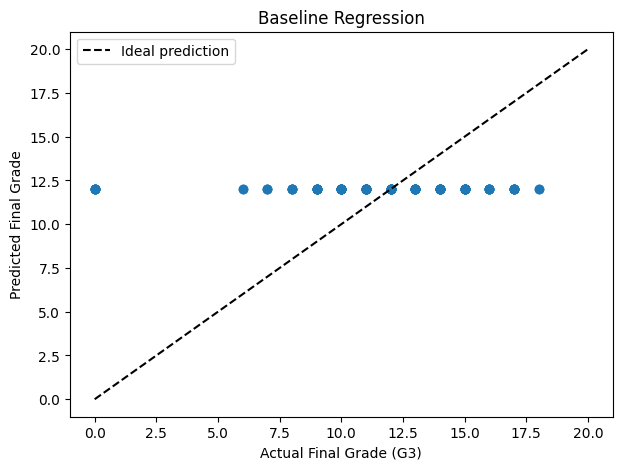

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.plot(
    [0, 20],
    [0, 20],
    color='black',
    linestyle='--',
    label='Ideal prediction'
)

plt.xlabel('Actual Final Grade (G3)')
plt.ylabel('Predicted Final Grade')

plt.title('Baseline Regression')

plt.legend()
plt.show()

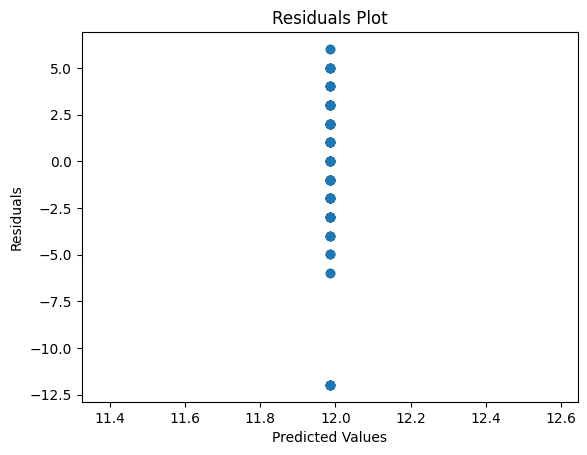

In [9]:
# Plotting residuals in order to check for any bias in the errors

residuals = y_test - predictions

plt.scatter(predictions, residuals)

plt.plot(
    [min(predictions), max(predictions)],
    [0, 0],
    color='black'
)

plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.title('Residuals Plot')

plt.show()